In [2]:
import pandas
%pip install geopandas
import matplotlib
%pip install shapely 
%pip install pyogrio 

   ---------------------------------------- 0.0/23.8 MB ? eta -:--:--
   --------------------------------- ------ 20.2/23.8 MB 106.5 MB/s eta 0:00:01
   ---------------------------------------- 23.8/23.8 MB 98.5 MB/s  0:00:00
   ---------------------------------------- 0.0/6.9 MB ? eta -:--:--
   ---------------------------------------- 6.9/6.9 MB 74.2 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 85.5 MB/s  0:00:00

   ---------------------------------------- 0/5 [shapely]
   ---------------------------------------- 0/5 [shapely]
   ---------------- ----------------------- 2/5 [pyproj]
   ------------------------ --------------- 3/5 [pyogrio]
   ------------------------ --------------- 3/5 [pyogrio]
   ------------------------ --------------- 3/5 [pyogrio]
   -------------------------------- ------- 4/5 [geopandas]
   -------------------------------- ------- 4/5 [geopandas]
   -----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas
import geopandas 
import matplotlib 
import shapely 
import pyogrio 

What i need each import for:

Pandas: reads and processes the .csv file 

GeoPandas: works with geographic coordinates and maps

Matplotlib: creates the visual representation

shapely: handles geographic shapes 

Pyogrio: Helps load geographic boundary files 


Total CSV rows: 5013589
Unique sensor locations: 700

Stations per region:
Region
1     28
2     35
3    286
4      8
5    138
6     91
7     24
8     90
Name: count, dtype: int64


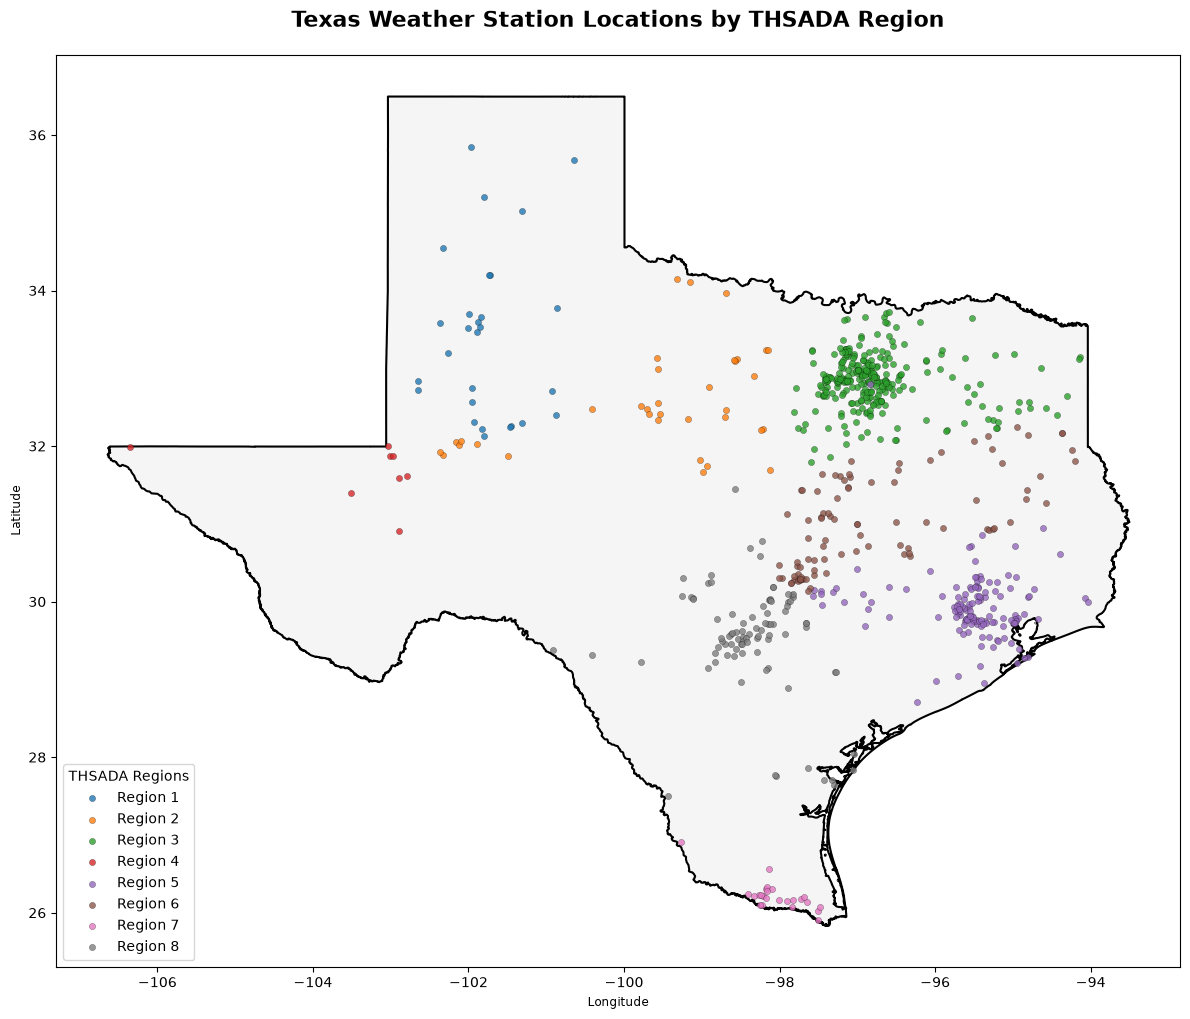


Map saved as texas_sensor_locations.png


In [5]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. LOAD THE CSV
# --------------------------------------------------

csv_file = "WBGT+HEAT.csv"  # Change to your CSV filename

# Only load the three columns we need.
# Column positions: Latitude=0, Longitude=1, Region=6

df = pd.read_csv(
    csv_file,
    usecols=[0, 1, 6]
)

df.columns = ["Latitude", "Longitude", "Region"]

# Convert columns to numeric values
df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")

# Extract region number (works with values like 1 or "Region 1")
df["Region"] = (
    df["Region"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
)

df["Region"] = pd.to_numeric(df["Region"], errors="coerce")

# Remove missing or invalid coordinates and regions
df = df.dropna(subset=["Latitude", "Longitude", "Region"])

df = df[
    df["Latitude"].between(-90, 90) &
    df["Longitude"].between(-180, 180) &
    df["Region"].between(1, 8)
]

# --------------------------------------------------
# 2. EXTRACT UNIQUE SENSOR LOCATIONS
# --------------------------------------------------

stations = df.drop_duplicates(
    subset=["Latitude", "Longitude", "Region"]
).copy()

print("Total CSV rows:", len(df))
print("Unique sensor locations:", len(stations))
print("\nStations per region:")
print(stations["Region"].value_counts().sort_index())

# --------------------------------------------------
# 3. LOAD TEXAS STATE BOUNDARY
# --------------------------------------------------

url = (
    "https://www2.census.gov/geo/tiger/GENZ2025/"
    "shp/cb_2025_us_state_500k.zip"
)

states = gpd.read_file(url)

# Extract Texas
texas = states[states["STUSPS"] == "TX"]

# --------------------------------------------------
# 4. CONVERT SENSOR COORDINATES TO GEOGRAPHIC POINTS
# --------------------------------------------------

points = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(
        stations["Longitude"],
        stations["Latitude"]
    ),
    crs="EPSG:4326"
)

# --------------------------------------------------
# 5. PLOT THE MAP
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 12))

# Draw Texas state boundary
texas.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=1.5
)

# Give each region a distinct color
colors = plt.cm.tab10.colors

for region in sorted(points["Region"].unique()):

    region_points = points[points["Region"] == region]

    ax.scatter(
        region_points.geometry.x,
        region_points.geometry.y,
        color=colors[int(region) - 1],
        label=f"Region {int(region)}",
        s=20,
        alpha=0.8,
        edgecolors="black",
        linewidths=0.2
    )

# Formatting
ax.set_title(
    "Texas Weather Station Locations by THSADA Region",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.legend(
    title="THSADA Regions",
    loc="lower left",
    fontsize=10
)

ax.set_aspect("equal")

plt.tight_layout()

# Save the map
plt.savefig(
    "texas_sensor_locations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nMap saved as texas_sensor_locations.png")


In [15]:

import pandas as pd
%pip install folium
import folium
import os
import webbrowser
from pathlib import Path
from collections import defaultdict

# =====================================================
# CONFIGURATION
# =====================================================

CSV_FILE = "WBGT+HEAT.csv"
CHUNK_SIZE = 200_000

OUTPUT_HTML = "texas_interactive_sensor_map.html"
OUTPUT_CSV = "texas_sensor_row_lookup.csv"

REGION_COLORS = {
    1: "red",
    2: "blue",
    3: "green",
    4: "orange",
    5: "purple",
    6: "darkred",
    7: "cadetblue",
    8: "pink"
}

# Each coordinate-region combination is a station
stations = {}

# =====================================================
# 1. READ CSV AND TRACK ORIGINAL ROW NUMBERS
# =====================================================

print("Reading sensor locations...")

row_offset = 0

for chunk in pd.read_csv(
    CSV_FILE,
    usecols=[0, 1, 6],
    chunksize=CHUNK_SIZE
):

    chunk.columns = ["Latitude", "Longitude", "Region"]

    chunk["Latitude"] = pd.to_numeric(
        chunk["Latitude"], errors="coerce"
    )

    chunk["Longitude"] = pd.to_numeric(
        chunk["Longitude"], errors="coerce"
    )

    chunk["Region"] = pd.to_numeric(
        chunk["Region"]
        .astype("string")
        .str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

    # Original Excel row numbers (header = row 1)
    chunk["Excel Row"] = range(
        row_offset + 2,
        row_offset + len(chunk) + 2
    )

    valid = chunk.dropna(
        subset=["Latitude", "Longitude", "Region"]
    ).copy()

    valid = valid[
        valid["Region"].isin(range(1, 9)) &
        valid["Latitude"].between(-90, 90) &
        valid["Longitude"].between(-180, 180)
    ]

    grouped = valid.groupby(
        ["Latitude", "Longitude", "Region"]
    ).agg(
        First_Row=("Excel Row", "min"),
        Observations=("Excel Row", "size")
    )

    for (lat, lon, region), record in grouped.iterrows():

        key = (float(lat), float(lon), int(region))

        if key not in stations:

            stations[key] = {
                "Latitude": float(lat),
                "Longitude": float(lon),
                "Region": int(region),
                "First CSV Row": int(record["First_Row"]),
                "Observations": int(record["Observations"])
            }

        else:

            stations[key]["First CSV Row"] = min(
                stations[key]["First CSV Row"],
                int(record["First_Row"])
            )

            stations[key]["Observations"] += int(
                record["Observations"]
            )

    row_offset += len(chunk)

print("Finished reading CSV.")
print("Unique coordinate-region combinations:", len(stations))

# =====================================================
# 2. SAVE STATION LOOKUP TABLE
# =====================================================

station_df = pd.DataFrame(stations.values())

station_df = station_df.sort_values(
    ["Region", "Latitude", "Longitude"]
)

station_df.to_csv(OUTPUT_CSV, index=False)

# =====================================================
# 3. GROUP IDENTICAL COORDINATES
#
# This is important: if the same coordinates appear
# under Region 3 AND Region 5, we show both assignments
# in one popup instead of hiding one underneath.
# =====================================================

coordinate_groups = defaultdict(list)

for station in stations.values():

    key = (
        station["Latitude"],
        station["Longitude"]
    )

    coordinate_groups[key].append(station)

# =====================================================
# 4. CREATE INTERACTIVE TEXAS MAP
# =====================================================

m = folium.Map(
    location=[31.0, -99.0],
    zoom_start=6,
    tiles="OpenStreetMap",
    control_scale=True,
    prefer_canvas=True
)

# One layer per region
layers = {}

for region in range(1, 9):

    layers[region] = folium.FeatureGroup(
        name=f"Region {region}",
        show=True
    )

# =====================================================
# 5. ADD CLICKABLE STATIONS
# =====================================================

print("Adding stations to interactive map...")

for (lat, lon), assignments in coordinate_groups.items():

    # Multiple region assignments at identical coordinates
    conflict = len(assignments) > 1

    if conflict:
        marker_color = "black"
    else:
        marker_color = REGION_COLORS[
            assignments[0]["Region"]
        ]

    # Build popup
    popup_html = f"""
    <div style="width: 260px; font-family: Arial;">
        <h3>Weather Station Location</h3>

        <b>Latitude:</b> {lat}<br>
        <b>Longitude:</b> {lon}<br>

        <hr>
    """

    if conflict:
        popup_html += """
        <h4 style="color:red;">
            WARNING: Multiple region assignments!
        </h4>
        """

    for station in assignments:

        popup_html += f"""
        <b>Assigned Region:</b> {station['Region']}<br>
        <b>First Excel/CSV Row:</b>
        {station['First CSV Row']}<br>
        <b>Total Observations:</b>
        {station['Observations']:,}<br>
        <hr>
        """

    popup_html += "</div>"

    popup = folium.Popup(
        popup_html,
        max_width=320
    )

    tooltip_text = (
        "Multiple region assignments"
        if conflict
        else f"Region {assignments[0]['Region']}"
    )

    # Place marker in appropriate region layer
    # For overlapping assignments, place it in Region 5
    # if applicable, otherwise the first assigned region.
    primary_region = (
        5 if any(s["Region"] == 5 for s in assignments)
        else assignments[0]["Region"]
    )

    folium.CircleMarker(
        location=[lat, lon],
        radius=7 if conflict else 5,
        color=marker_color,
        fill=True,
        fill_color=marker_color,
        fill_opacity=0.9,
        weight=2 if conflict else 1,
        popup=popup,
        tooltip=tooltip_text
    ).add_to(layers[primary_region])

# Add all region layers
for layer in layers.values():
    layer.add_to(m)

# Layer selection
folium.LayerControl(
    collapsed=False
).add_to(m)

# =====================================================
# 6. ADD MAP LEGEND
# =====================================================

legend_html = """
<div style="
position: fixed;
bottom: 30px;
left: 30px;
z-index: 9999;
background: white;
padding: 12px;
border: 2px solid grey;
border-radius: 6px;
font-family: Arial;
font-size: 13px;
">
<b>THSADA Regions</b><br>
"""

for region, color in REGION_COLORS.items():

    legend_html += (
        f'<span style="color:{color};">●</span> '
        f'Region {region}<br>'
    )

legend_html += """
<span style="color:black;">●</span>
Multiple region assignments
</div>
"""

m.get_root().html.add_child(
    folium.Element(legend_html)
)

# =====================================================
# 7. SAVE AND OPEN MAP
# =====================================================

m.save(OUTPUT_HTML)

print("\nMap successfully generated!")
print("Interactive map:", os.path.abspath(OUTPUT_HTML))
print("Station lookup:", os.path.abspath(OUTPUT_CSV))

# Open map in default browser
webbrowser.open_new_tab(
    Path(OUTPUT_HTML).resolve().as_uri()
)

print("\nClick a station marker to see its original CSV row.")


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.



   ----------- ---------------------------- 2/7 [idna]
   ----------------- ---------------------- 3/7 [charset_normalizer]
   ---------------------------------- ----- 6/7 [folium]
   ---------------------------------------- 7/7 [folium]

Note: you may need to restart the kernel to use updated packages.
Reading sensor locations...
Finished reading CSV.
Unique coordinate-region combinations: 700
Adding stations to interactive map...

Map successfully generated!
Interactive map: d:\ResearchCS\Texas Heat Stress\Code\texas_interactive_sensor_map.html
Station lookup: d:\ResearchCS\Texas Heat Stress\Code\texas_sensor_row_lookup.csv

Click a station marker to see its original CSV row.


In [ ]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# =========================================================
# CONFIGURATION
# =========================================================

CSV_FILE = "WBGT+HEAT.csv"

CHUNK_SIZE = 200_000

START_DATE = pd.Timestamp("2026-05-01")
END_DATE = pd.Timestamp("2026-10-01")  # Exclusive

REGIONS = list(range(1, 9))

OUTPUT_FOLDER = "stage2_charts"

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# Consistent colors for all eight regions
cmap = plt.get_cmap("tab10")
REGION_COLORS = {
    r: cmap(r - 1) for r in REGIONS
}

# =========================================================
# INITIALIZE DATA STRUCTURES
# =========================================================

observation_counts = Counter()

# Station identity: (region, latitude, longitude)
station_observations = Counter()

wbgt_data = {r: [] for r in REGIONS}
heat_data = {r: [] for r in REGIONS}

total_rows_in_period = 0
invalid_timestamps = 0
invalid_regions = 0

# =========================================================
# READ CSV IN CHUNKS
# =========================================================

print("Starting data processing...")

for chunk in pd.read_csv(
    CSV_FILE,
    usecols=[0, 1, 3, 4, 5, 6],
    chunksize=CHUNK_SIZE
):

    chunk.columns = [
        "Latitude",
        "Longitude",
        "LocalTime",
        "WBGT",
        "HeatIndex",
        "Region"
    ]

    # Convert numerical fields
    for col in [
        "Latitude",
        "Longitude",
        "WBGT",
        "HeatIndex"
    ]:
        chunk[col] = pd.to_numeric(
            chunk[col], errors="coerce"
        )

    # Extract region number
    chunk["Region"] = pd.to_numeric(
        chunk["Region"]
        .astype("string")
        .str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

    # Parse local observation time
    local_time = pd.to_datetime(
        chunk["LocalTime"],
        errors="coerce"
    )

    # If timestamps contain timezone information,
    # remove it while preserving the displayed local time.
    if isinstance(local_time.dtype, pd.DatetimeTZDtype):
        local_time = local_time.dt.tz_localize(None)

    invalid_timestamps += int(local_time.isna().sum())

    # Filter to the research period
    in_period = (
        local_time.ge(START_DATE) &
        local_time.lt(END_DATE)
    )

    chunk = chunk.loc[in_period].copy()

    total_rows_in_period += len(chunk)

    # Keep valid regions
    valid_region = chunk["Region"].isin(REGIONS)

    invalid_regions += int((~valid_region).sum())

    chunk = chunk.loc[valid_region].copy()
    chunk["Region"] = chunk["Region"].astype(int)

    # =====================================================
    # PROCESS EACH REGION
    # =====================================================

    for region, group in chunk.groupby("Region"):

        # Total 30-minute observations
        observation_counts[region] += len(group)

        # WBGT values
        wbgt = group["WBGT"].dropna().to_numpy()

        if len(wbgt):
            wbgt_data[region].append(wbgt)

        # Heat index values
        heat = group["HeatIndex"].dropna().to_numpy()

        if len(heat):
            heat_data[region].append(heat)

        # Count observations per unique station
        valid_stations = group.dropna(
            subset=["Latitude", "Longitude"]
        )

        station_groups = (
            valid_stations
            .groupby(["Latitude", "Longitude"])
            .size()
        )

        for (lat, lon), count in station_groups.items():

            key = (region, float(lat), float(lon))

            station_observations[key] += int(count)

print("\nData processing complete!")

# =========================================================
# PREPARE DATA FOR VISUALIZATION
# =========================================================

station_counts = {
    r: sum(
        1 for key in station_observations
        if key[0] == r
    )
    for r in REGIONS
}

observations = [
    observation_counts[r] for r in REGIONS
]

stations = [
    station_counts[r] for r in REGIONS
]

station_coverage = {
    r: [
        count
        for (region, lat, lon), count
        in station_observations.items()
        if region == r
    ]
    for r in REGIONS
}

def combine_data(data_dict):
    result = {}

    for region in REGIONS:
        if data_dict[region]:
            result[region] = np.concatenate(
                data_dict[region]
            )
        else:
            result[region] = np.array([])

    return result


wbgt_data = combine_data(wbgt_data)
heat_data = combine_data(heat_data)

# =========================================================
# HELPER: SAVE CHART
# =========================================================

def save_chart(fig, filename):

    path = os.path.join(
        OUTPUT_FOLDER,
        filename
    )

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Saved:", path)


# =========================================================
# CHART 1: NUMBER OF SENSORS PER REGION
# =========================================================

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    REGIONS,
    stations,
    color=[REGION_COLORS[r] for r in REGIONS]
)

ax.set_title(
    "Number of Weather Stations per THSADA Region",
    fontsize=15,
    pad=15
)

ax.set_xlabel("THSADA Region")
ax.set_ylabel("Number of Unique Stations")

ax.set_xticks(REGIONS)
ax.grid(axis="y", alpha=0.25)

ax.bar_label(bars, padding=3)

save_chart(fig, "01_sensors_per_region.png")


# =========================================================
# CHART 2: TOTAL OBSERVATIONS PER REGION
# =========================================================

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    REGIONS,
    observations,
    color=[REGION_COLORS[r] for r in REGIONS]
)

ax.set_title(
    "Total 30-Minute Observations per Region",
    fontsize=15,
    pad=15
)

ax.set_xlabel("THSADA Region")
ax.set_ylabel("Number of Observations")

ax.set_xticks(REGIONS)
ax.grid(axis="y", alpha=0.25)

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in observations],
    padding=3
)

save_chart(fig, "02_observations_per_region.png")


# =========================================================
# CHART 3: OBSERVATIONS PER STATION
# =========================================================

plot_data = []
plot_labels = []

for region in REGIONS:

    values = station_coverage[region]

    if values:
        plot_data.append(values)
        plot_labels.append(str(region))

fig, ax = plt.subplots(figsize=(11, 6))

bp = ax.boxplot(
    plot_data,
    tick_labels=plot_labels,
    patch_artist=True,
    showfliers=False
)

for patch, region in zip(bp["boxes"], map(int, plot_labels)):
    patch.set_facecolor(REGION_COLORS[region])

ax.set_title(
    "30-Minute Observations per Station by Region",
    fontsize=15,
    pad=15
)

ax.set_xlabel("THSADA Region")
ax.set_ylabel("Observations per Station")

ax.grid(axis="y", alpha=0.25)

save_chart(fig, "03_station_coverage.png")


# =========================================================
# HELPER: REGIONAL TEMPERATURE BOXPLOTS
# =========================================================

def create_regional_boxplot(
    data,
    title,
    ylabel,
    filename
):

    plot_data = []
    plot_labels = []

    for region in REGIONS:

        values = data[region]

        if len(values):
            plot_data.append(values)
            plot_labels.append(str(region))

    fig, ax = plt.subplots(figsize=(11, 6))

    bp = ax.boxplot(
        plot_data,
        tick_labels=plot_labels,
        patch_artist=True,
        showfliers=False,
        whis=(5, 95)
    )

    for patch, region in zip(
        bp["boxes"], map(int, plot_labels)
    ):
        patch.set_facecolor(REGION_COLORS[region])

    ax.set_title(title, fontsize=15, pad=15)

    ax.set_xlabel("THSADA Region")
    ax.set_ylabel(ylabel)

    ax.grid(axis="y", alpha=0.25)

    save_chart(fig, filename)


# =========================================================
# CHART 4: WBGT DISTRIBUTION
# =========================================================

create_regional_boxplot(
    data=wbgt_data,
    title="WBGT Distribution Across THSADA Regions",
    ylabel="Average WBGT (°F)",
    filename="04_wbgt_distribution.png"
)


# =========================================================
# CHART 5: HEAT INDEX DISTRIBUTION
# =========================================================

create_regional_boxplot(
    data=heat_data,
    title="Heat Index Distribution Across THSADA Regions",
    ylabel="Average Heat Index (°F)",
    filename="05_heat_index_distribution.png"
)


# =========================================================
# ADDITIONAL NUMERICAL SUMMARY
# =========================================================

summary = []

for region in REGIONS:

    w = wbgt_data[region]
    h = heat_data[region]

    summary.append({
        "Region": region,
        "Stations": station_counts[region],
        "Observations": observation_counts[region],

        "WBGT Mean": np.mean(w) if len(w) else np.nan,
        "WBGT Median": np.median(w) if len(w) else np.nan,
        "WBGT 95th Percentile": (
            np.percentile(w, 95) if len(w) else np.nan
        ),

        "Heat Index Mean": (
            np.mean(h) if len(h) else np.nan
        ),
        "Heat Index Median": (
            np.median(h) if len(h) else np.nan
        ),
        "Heat Index 95th Percentile": (
            np.percentile(h, 95) if len(h) else np.nan
        )
    })

summary_df = pd.DataFrame(summary).round(2)

summary_df.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "regional_visualization_summary.csv"
    ),
    index=False
)

# =========================================================
# FINAL REPORT
# =========================================================

print("\n" + "=" * 55)
print("STAGE 2 VISUALIZATION REPORT")
print("=" * 55)

print("Rows within study period:", total_rows_in_period)
print("Invalid timestamps in CSV:", invalid_timestamps)
print("Invalid region assignments in study period:", invalid_regions)

print("\nREGIONAL SUMMARY:")
print(summary_df.to_string(index=False))

print("\nAll visualizations saved in:", OUTPUT_FOLDER)

print("\nStage 2 visualization process complete!")


Starting data processing...

Data processing complete!
Saved: stage2_charts\01_sensors_per_region.png
Saved: stage2_charts\02_observations_per_region.png
Saved: stage2_charts\03_station_coverage.png
Saved: stage2_charts\04_wbgt_distribution.png
Saved: stage2_charts\05_heat_index_distribution.png

STAGE 2 VISUALIZATION REPORT
Rows within study period: 5013589
Invalid timestamps in CSV: 0
Invalid region assignments in study period: 0

REGIONAL SUMMARY:
 Region  Stations  Observations  WBGT Mean  WBGT Median  WBGT 95th Percentile  Heat Index Mean  Heat Index Median  Heat Index 95th Percentile
      1        28        195306      72.81        72.88                 85.73            79.99              80.55                       96.73
      2        35        244376      76.49        76.32                 88.12            83.93              84.27                      100.98
      3       286       2089217      78.93        78.96                 90.41            87.37              87.94      

In [8]:

import os
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# CONFIGURATION
# =========================================================

CSV_FILE = "WBGT+HEAT.csv"
CHUNK_SIZE = 200_000

START_DATE = pd.Timestamp("2026-05-01")
END_DATE = pd.Timestamp("2026-10-01")  # Exclusive

REGIONS = range(1, 9)

OUTPUT_FOLDER = "stage3_wbgt_charts"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# Consistent color for each region
cmap = plt.get_cmap("tab10")
COLORS = {r: cmap(r - 1) for r in REGIONS}

# =========================================================
# REGIONAL COUNTS
# =========================================================

observation_counts = defaultdict(int)
wbgt_counts = defaultdict(int)
station_locations = {r: set() for r in REGIONS}

# =========================================================
# AGGREGATION STORAGE
#
# We calculate station-level averages first.
# Then each station gets equal weight in its region.
# =========================================================

time_sums = defaultdict(float)
time_counts = defaultdict(int)

month_sums = defaultdict(float)
month_counts = defaultdict(int)

day_sums = defaultdict(float)
day_counts = defaultdict(int)


def accumulate(frame, group_columns, region, sums, counts):
    """Accumulate WBGT sums and counts for each station/time bucket."""

    grouped = frame.groupby(
        group_columns
    )["WBGT"].agg(["sum", "count"])

    for key, row in grouped.iterrows():

        if not isinstance(key, tuple):
            key = (key,)

        full_key = (region,) + tuple(key)

        sums[full_key] += float(row["sum"])
        counts[full_key] += int(row["count"])


# =========================================================
# READ THE ORIGINAL CSV IN CHUNKS
# =========================================================

print("Reading Texas weather data...")

total_rows = 0
invalid_timestamps = 0

for chunk in pd.read_csv(
    CSV_FILE,
    usecols=[0, 1, 3, 4, 6],
    chunksize=CHUNK_SIZE
):

    chunk.columns = [
        "Latitude",
        "Longitude",
        "LocalTime",
        "WBGT",
        "Region"
    ]

    # Convert numerical fields
    for col in ["Latitude", "Longitude", "WBGT"]:
        chunk[col] = pd.to_numeric(
            chunk[col], errors="coerce"
        )

    # Extract region numbers
    chunk["Region"] = pd.to_numeric(
        chunk["Region"]
        .astype("string")
        .str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

    # Parse local time
    local_time = pd.to_datetime(
        chunk["LocalTime"],
        errors="coerce"
    )

    # Preserve the displayed local clock time if timezone-aware
    if isinstance(local_time.dtype, pd.DatetimeTZDtype):
        local_time = local_time.dt.tz_localize(None)

    invalid_timestamps += int(local_time.isna().sum())

    # Filter May 1 through September 30
    period_mask = (
        local_time.ge(START_DATE) &
        local_time.lt(END_DATE)
    )

    chunk = chunk.loc[period_mask].copy()
    chunk["_LocalDT"] = local_time.loc[period_mask]

    # Keep valid region assignments
    chunk = chunk[
        chunk["Region"].isin(REGIONS)
    ].copy()

    chunk["Region"] = chunk["Region"].astype(int)

    total_rows += len(chunk)

    # Create temporal grouping variables
    chunk["Date"] = chunk["_LocalDT"].dt.normalize()
    chunk["Month"] = chunk["_LocalDT"].dt.month

    # 0 through 47, representing 48 half-hour intervals
    chunk["TimeSlot"] = (
        chunk["_LocalDT"].dt.hour * 2 +
        chunk["_LocalDT"].dt.minute // 30
    )

    # Process each region
    for region, group in chunk.groupby("Region"):

        observation_counts[region] += len(group)

        wbgt_counts[region] += int(
            group["WBGT"].notna().sum()
        )

        # Unique station locations
        locations = group.dropna(
            subset=["Latitude", "Longitude"]
        )

        station_locations[region].update(
            zip(
                locations["Latitude"].astype(float),
                locations["Longitude"].astype(float)
            )
        )

        # Only valid WBGT records with identifiable stations
        valid = group.dropna(
            subset=["Latitude", "Longitude", "WBGT"]
        )

        if valid.empty:
            continue

        # Average station WBGT by time of day
        accumulate(
            valid,
            ["Latitude", "Longitude", "TimeSlot"],
            region,
            time_sums,
            time_counts
        )

        # Average station WBGT by month
        accumulate(
            valid,
            ["Latitude", "Longitude", "Month"],
            region,
            month_sums,
            month_counts
        )

        # Average station WBGT by calendar day
        accumulate(
            valid,
            ["Latitude", "Longitude", "Date"],
            region,
            day_sums,
            day_counts
        )

print("\nFinished processing the CSV.")

# =========================================================
# 2. PRINT REGIONAL STATION AND OBSERVATION COUNTS
# =========================================================

report = []

for region in REGIONS:

    report.append({
        "Region": region,
        "Unique Stations": len(station_locations[region]),
        "30-Minute Observations": observation_counts[region],
        "Valid WBGT Observations": wbgt_counts[region]
    })

report_df = pd.DataFrame(report)

print("\n" + "=" * 65)
print("TEXAS WEATHER STATION COUNTS BY REGION")
print("=" * 65)

print(report_df.to_string(index=False))

print("\nTotal observations:", f"{total_rows:,}")
print("Invalid timestamps in entire CSV:", f"{invalid_timestamps:,}")

report_df.to_csv(
    os.path.join(
        OUTPUT_FOLDER,
        "regional_station_counts.csv"
    ),
    index=False
)

# =========================================================
# 3. CALCULATE STATION-WEIGHTED REGIONAL AVERAGES
# =========================================================

def calculate_regional_means(sums, counts):
    """
    First calculates each station's average for a time bucket.
    Then averages those station means within each region.

    This prevents stations with more observations from
    automatically receiving more statistical weight.
    """

    station_means = defaultdict(list)

    for key, total in sums.items():

        region, latitude, longitude, bucket = key

        count = counts[key]

        if count > 0:
            station_means[
                (region, bucket)
            ].append(total / count)

    return {
        key: float(np.mean(values))
        for key, values in station_means.items()
    }


time_means = calculate_regional_means(
    time_sums, time_counts
)

month_means = calculate_regional_means(
    month_sums, month_counts
)

day_means = calculate_regional_means(
    day_sums, day_counts
)

# =========================================================
# HELPER: COMMON CHART FORMATTING
# =========================================================

def format_chart(ax, title, ylabel):

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_ylabel(ylabel, fontsize=11)
    ax.grid(True, alpha=0.25)

    ax.legend(
        title="THSADA Region",
        ncol=2,
        fontsize=9
    )

# =========================================================
# CHART 1: WBGT THROUGHOUT THE DAY
# =========================================================

fig, ax = plt.subplots(figsize=(13, 7))

time_slots = list(range(48))

time_labels = [
    f"{i // 2:02d}:{(i % 2) * 30:02d}"
    for i in time_slots
]

for region in REGIONS:

    y = [
        time_means.get((region, slot), np.nan)
        for slot in time_slots
    ]

    ax.plot(
        time_slots,
        y,
        color=COLORS[region],
        linewidth=2,
        label=f"Region {region}"
    )

ax.set_xticks(range(0, 48, 4))
ax.set_xticklabels(
    [time_labels[i] for i in range(0, 48, 4)]
)

ax.set_xlabel("Local Time of Day")

format_chart(
    ax,
    "Average WBGT Throughout the Day by Region",
    "Average WBGT (°F)"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "01_wbgt_throughout_day.png"
    ),
    dpi=300
)

plt.close(fig)

# =========================================================
# CHART 2: WBGT BY MONTH
# =========================================================

fig, ax = plt.subplots(figsize=(11, 7))

months = [5, 6, 7, 8, 9]

month_labels = [
    "May",
    "June",
    "July",
    "August",
    "September"
]

for region in REGIONS:

    y = [
        month_means.get((region, month), np.nan)
        for month in months
    ]

    ax.plot(
        months,
        y,
        marker="o",
        markersize=6,
        linewidth=2,
        color=COLORS[region],
        label=f"Region {region}"
    )

ax.set_xticks(months)
ax.set_xticklabels(month_labels)

ax.set_xlabel("Month")

format_chart(
    ax,
    "Average Monthly WBGT by Region",
    "Average WBGT (°F)"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "02_wbgt_by_month.png"
    ),
    dpi=300
)

plt.close(fig)

# =========================================================
# CHART 3: WBGT THROUGHOUT THE SUMMER
# =========================================================

fig, ax = plt.subplots(figsize=(15, 7))

dates = pd.date_range(
    START_DATE,
    END_DATE - pd.Timedelta(days=1),
    freq="D"
)

for region in REGIONS:

    daily_values = [
        day_means.get(
            (region, date),
            np.nan
        )
        for date in dates
    ]

    daily_series = pd.Series(
        daily_values,
        index=dates
    )

    # Seven-calendar-day rolling average
    rolling_average = daily_series.rolling(
        window=7,
        center=True,
        min_periods=1
    ).mean()

    ax.plot(
        dates,
        rolling_average,
        linewidth=2,
        color=COLORS[region],
        label=f"Region {region}"
    )

ax.set_xlabel("Date")

ax.xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %d")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

format_chart(
    ax,
    "WBGT Trends Throughout Summer 2026 (7-Day Rolling Average)",
    "Average WBGT (°F)"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        OUTPUT_FOLDER,
        "03_wbgt_throughout_summer.png"
    ),
    dpi=300
)

plt.close(fig)

# =========================================================
# FINISHED
# =========================================================

print("\n" + "=" * 65)
print("ALL THREE WBGT LINE PLOTS GENERATED!")
print("=" * 65)

print("\nOutput folder:", OUTPUT_FOLDER)

print("\nGenerated charts:")
print("1. 01_wbgt_throughout_day.png")
print("2. 02_wbgt_by_month.png")
print("3. 03_wbgt_throughout_summer.png")
print("4. regional_station_counts.csv")


Reading Texas weather data...

Finished processing the CSV.

TEXAS WEATHER STATION COUNTS BY REGION
 Region  Unique Stations  30-Minute Observations  Valid WBGT Observations
      1               28                  195306                   195070
      2               35                  244376                   244052
      3              286                 2089217                  2085520
      4                8                   57020                    56974
      5              138                  977475                   974292
      6               91                  637840                   637015
      7               24                  164912                   164630
      8               90                  647443                   646340

Total observations: 5,013,589
Invalid timestamps in entire CSV: 0

ALL THREE WBGT LINE PLOTS GENERATED!

Output folder: stage3_wbgt_charts

Generated charts:
1. 01_wbgt_throughout_day.png
2. 02_wbgt_by_month.png
3. 03_wbgt_throughout